In [53]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import csv
import os


from src.evaluation.cross_validation import stratified_k_fold
from src.evaluation.evaluator import ModelEvaluator
from src.evaluation.model_comparison import ModelComparison, format_comparison_table
from src.reporting.visualization import plot_model_comparison
from src.data_prep.preprocessing import preproc_MSCOHE
from src.evaluation.threshold_tuning import ThresholdTuner
from src.evaluation.holdout import HoldoutEvaluator
from src.data_prep.feature_selection import feature_selection
from src.data_prep.train_test_split import TrainTestSplit,prepare_development_and_holdout
from src.reporting.visualization import plot_model_comparison



In [39]:
print("Répertoire courant :", Path.cwd())
print("Dossier data existe :", Path("data").exists())

Répertoire courant : /Users/mathildec.gallego/Desktop/EPFL/Master/MA1/MachineLearning/Cardiovascular-Risk-Prediction
Dossier data existe : True


In [40]:
# notebooks/model_selection.ipynb

# 1. data

splitter = TrainTestSplit(train_size=0.6, val_size=0.2, test_size=0.2, seed=42)
parts = splitter.split_csv()          
development, holdout = prepare_development_and_holdout(parts)
X_dev, y_dev = development["X"], development["y"]
X_hold, y_hold = holdout["X"], holdout["y"]
print(X_dev.shape, y_dev.shape, X_hold.shape, y_hold.shape)


(262508, 321) (262508,) (65627, 321) (65627,)


In [41]:

# 2. shared folds

folds = stratified_k_fold(y_dev, k=5, seed=42)
print(len(folds), "folds")


5 folds


In [42]:
with open(os.path.join("data", "x_train.csv"), newline="") as f:
    labels = next(csv.reader(f))
labels = labels[1:]

In [43]:
labels

['_STATE',
 'FMONTH',
 'IDATE',
 'IMONTH',
 'IDAY',
 'IYEAR',
 'DISPCODE',
 'SEQNO',
 '_PSU',
 'CTELENUM',
 'PVTRESD1',
 'COLGHOUS',
 'STATERES',
 'CELLFON3',
 'LADULT',
 'NUMADULT',
 'NUMMEN',
 'NUMWOMEN',
 'CTELNUM1',
 'CELLFON2',
 'CADULT',
 'PVTRESD2',
 'CCLGHOUS',
 'CSTATE',
 'LANDLINE',
 'HHADULT',
 'GENHLTH',
 'PHYSHLTH',
 'MENTHLTH',
 'POORHLTH',
 'HLTHPLN1',
 'PERSDOC2',
 'MEDCOST',
 'CHECKUP1',
 'BPHIGH4',
 'BPMEDS',
 'BLOODCHO',
 'CHOLCHK',
 'TOLDHI2',
 'CVDSTRK3',
 'ASTHMA3',
 'ASTHNOW',
 'CHCSCNCR',
 'CHCOCNCR',
 'CHCCOPD1',
 'HAVARTH3',
 'ADDEPEV2',
 'CHCKIDNY',
 'DIABETE3',
 'DIABAGE2',
 'SEX',
 'MARITAL',
 'EDUCA',
 'RENTHOM1',
 'NUMHHOL2',
 'NUMPHON2',
 'CPDEMO1',
 'VETERAN3',
 'EMPLOY1',
 'CHILDREN',
 'INCOME2',
 'INTERNET',
 'WEIGHT2',
 'HEIGHT3',
 'PREGNANT',
 'QLACTLM2',
 'USEEQUIP',
 'BLIND',
 'DECIDE',
 'DIFFWALK',
 'DIFFDRES',
 'DIFFALON',
 'SMOKE100',
 'SMOKDAY2',
 'STOPSMK2',
 'LASTSMK2',
 'USENOW3',
 'ALCDAY5',
 'AVEDRNK2',
 'DRNK3GE5',
 'MAXDRNKS',
 'FRUITJU

In [44]:
#2.5a input prep 

#imagine for a second that there is a feature_selection.py and a function select_features(X) -> (X_subset, num_mask, cat_mask, kept_names)
X_dev_sub, KEPT_NAMES, NUM_MASK, CAT_MASK = feature_selection(
    X_dev, labels,   # feature_names
)
print(f"{X_dev_sub.shape[1]} features retenues "
      f"({NUM_MASK.sum()} num, {CAT_MASK.sum()} cat)")
      


53 features retenues (10 num, 43 cat)


In [45]:
#2.5b input prep 
assert (NUM_MASK & CAT_MASK).sum() == 0
assert (NUM_MASK | CAT_MASK).sum() == X_dev_sub.shape[1]

factory = lambda: preproc_MSCOHE(num_inputs=NUM_MASK, cat_inputs=CAT_MASK)

In [46]:

# 3. baseline comparison


candidates = {
    "Baseline":             ModelEvaluator("always_negative_baseline"),
    "Least squares":        ModelEvaluator("least_squares"),
    "MSE (GD)":             ModelEvaluator("mean_squared_error_gd", max_it=1000, gamma=0.01),
    "MSE (SGD)":            ModelEvaluator("mean_squared_error_sgd", max_it=1000, gamma=0.01, seed=42),
    "Ridge":                ModelEvaluator("ridge_regression", lmbd=1e-6),
    "Logistic":             ModelEvaluator("logistic_regression", max_it=1000, gamma=0.01),
    "Regularized logistic": ModelEvaluator("reg_logistic_regression", lmbd=1e-6, max_it=1000, gamma=0.01),
    "Linear SVM":           ModelEvaluator("svm", lmbd=1e-6, max_it=1000, gamma=0.01),
}
comparison = ModelComparison(candidates, folds, fold_seed=42,
                             preprocessor_factory=factory)
results = comparison.run(X_dev_sub, y_dev)
print(format_comparison_table(results))


| Model | F1 | Precision | Recall | Accuracy | ROC-AUC |
| --- | --- | --- | --- | --- | --- |
| MSE (SGD) | 0.1238 ± 0.0903 | 0.2557 ± 0.1577 | 0.1004 ± 0.0958 | 0.8976 ± 0.0200 | 0.7282 ± 0.0554 |
| Ridge | 0.0917 ± 0.0028 | 0.6686 ± 0.0142 | 0.0492 ± 0.0016 | 0.9139 ± 0.0002 | 0.8512 ± 0.0015 |
| Least squares | 0.0917 ± 0.0028 | 0.6678 ± 0.0143 | 0.0492 ± 0.0016 | 0.9139 ± 0.0002 | 0.8512 ± 0.0015 |
| Logistic | 0.0449 ± 0.0039 | 0.6374 ± 0.0284 | 0.0233 ± 0.0021 | 0.9126 ± 0.0002 | 0.8309 ± 0.0018 |
| Regularized logistic | 0.0449 ± 0.0039 | 0.6374 ± 0.0284 | 0.0233 ± 0.0021 | 0.9126 ± 0.0002 | 0.8309 ± 0.0018 |
| MSE (GD) | 0.0310 ± 0.0020 | 0.7574 ± 0.0414 | 0.0158 ± 0.0010 | 0.9126 ± 0.0001 | 0.8495 ± 0.0016 |
| Baseline | 0.0000 ± 0.0000 | 0.0000 ± 0.0000 | 0.0000 ± 0.0000 | 0.9117 ± 0.0000 | 0.5000 ± 0.0000 |
| Linear SVM | 0.0000 ± 0.0000 | 0.0000 ± 0.0000 | 0.0000 ± 0.0000 | 0.9117 ± 0.0000 | 0.8250 ± 0.0019 |


In [47]:
print("nan dans X_dev :", np.isnan(X_dev_sub).sum())
print("nan dans y_dev :", np.isnan(y_dev).sum())
print("shape X_dev :", X_dev.shape)

nan dans X_dev : 696320
nan dans y_dev : 0
shape X_dev : (262508, 321)


In [48]:

# 4. Tuning hyperparams 
# choose 2/3 models and select of few configs for them 
configurations = {
    "ridge_regression": [{"lmbd": l} for l in (1e-6, 1e-5, 1e-4, 1e-3, 1e-2)],
    "reg_logistic_regression": [
        {"lmbd": 1e-6, "max_it": 3000, "gamma": 0.05},
        {"lmbd": 1e-5, "max_it": 3000, "gamma": 0.05},
        {"lmbd": 1e-4, "max_it": 3000, "gamma": 0.05},
        {"lmbd": 1e-3, "max_it": 3000, "gamma": 0.05},
        {"lmbd": 1e-2, "max_it": 3000, "gamma": 0.05},
    ],
}
comparison2 = ModelComparison.from_configurations(
    configurations, folds, fold_seed=42, preprocessor_factory=factory,
)
tuned = comparison2.run(X_dev_sub, y_dev)
print(format_comparison_table(tuned))


| Model | F1 | Precision | Recall | Accuracy | ROC-AUC |
| --- | --- | --- | --- | --- | --- |
| reg_logistic_regression [1] (lmbd=1e-06, max_it=3000, gamma=0.05) | 0.2097 ± 0.0076 | 0.5611 ± 0.0110 | 0.1289 ± 0.0054 | 0.9142 ± 0.0005 | 0.8546 ± 0.0017 |
| reg_logistic_regression [2] (lmbd=1e-05, max_it=3000, gamma=0.05) | 0.2094 ± 0.0075 | 0.5608 ± 0.0107 | 0.1287 ± 0.0052 | 0.9142 ± 0.0004 | 0.8546 ± 0.0017 |
| reg_logistic_regression [3] (lmbd=0.0001, max_it=3000, gamma=0.05) | 0.2082 ± 0.0073 | 0.5624 ± 0.0098 | 0.1277 ± 0.0052 | 0.9142 ± 0.0004 | 0.8545 ± 0.0017 |
| reg_logistic_regression [4] (lmbd=0.001, max_it=3000, gamma=0.05) | 0.1939 ± 0.0064 | 0.5680 ± 0.0080 | 0.1170 ± 0.0044 | 0.9142 ± 0.0003 | 0.8538 ± 0.0017 |
| reg_logistic_regression [5] (lmbd=0.01, max_it=3000, gamma=0.05) | 0.1020 ± 0.0033 | 0.6073 ± 0.0095 | 0.0557 ± 0.0020 | 0.9134 ± 0.0001 | 0.8468 ± 0.0017 |
| ridge_regression [1] (lmbd=1e-06) | 0.0917 ± 0.0028 | 0.6686 ± 0.0142 | 0.0492 ± 0.0016 | 0.9139 ± 0.00

We can see that regularisation on logistic regression doesn't help, the lower the lambda the better. Traditional logistic regression will perform better. 
Same thing with ridge regression so we'll stick with least squares.

In [ ]:

# 5. Tuning thr

tuner = ThresholdTuner(
    {
        "least_squares":           [-0.5, -0.25, 0.0, 0.25, 0.5],
        "ridge_regression":        [-0.5, -0.25, 0.0, 0.25, 0.5],
        "logistic_regression":     [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
        "reg_logistic_regression": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
        "svm":                     [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0],
    },
    folds,
)
tuned_thr = tuner.run(tuned, y_dev)
print(format_comparison_table(tuned_thr))


| Model | F1 | Precision | Recall | Accuracy | ROC-AUC |
| --- | --- | --- | --- | --- | --- |
| reg_logistic_regression [1] (lmbd=1e-06, max_it=3000, gamma=0.05) | 0.4185 ± 0.0017 | 0.3504 ± 0.0019 | 0.5193 ± 0.0034 | 0.8725 ± 0.0008 | 0.8546 ± 0.0017 |
| reg_logistic_regression [2] (lmbd=1e-05, max_it=3000, gamma=0.05) | 0.4185 ± 0.0018 | 0.3504 ± 0.0019 | 0.5193 ± 0.0035 | 0.8725 ± 0.0008 | 0.8546 ± 0.0017 |
| reg_logistic_regression [3] (lmbd=0.0001, max_it=3000, gamma=0.05) | 0.4182 ± 0.0016 | 0.3504 ± 0.0017 | 0.5188 ± 0.0036 | 0.8726 ± 0.0007 | 0.8545 ± 0.0017 |
| reg_logistic_regression [4] (lmbd=0.001, max_it=3000, gamma=0.05) | 0.4162 ± 0.0013 | 0.3500 ± 0.0018 | 0.5134 ± 0.0027 | 0.8728 ± 0.0007 | 0.8538 ± 0.0017 |
| ridge_regression [4] (lmbd=0.001) | 0.4056 ± 0.0026 | 0.3810 ± 0.0025 | 0.4336 ± 0.0042 | 0.8878 ± 0.0007 | 0.8513 ± 0.0015 |
| ridge_regression [2] (lmbd=1e-05) | 0.4054 ± 0.0018 | 0.3798 ± 0.0020 | 0.4346 ± 0.0033 | 0.8874 ± 0.0006 | 0.8512 ± 0.0015 |
| ridge_

In [ ]:
# Fusion : from results, override Ridge et RegLog with their tuned versions
merged = dict(results)   # copy of results

# Add tuned version of Ridge and RegLog (and override baseline versions)
for name, res in tuned.items():
    method = res["configuration"]["method"]
    if method == "ridge_regression":
        merged["Ridge (tuned λ=1e-6)"] = res
    elif method == "reg_logistic_regression":
        merged["Reg. logistic (tuned λ=1e-6)"] = res

# Remove basline versions of Ridge et RegLog 
merged.pop("Ridge", None)
merged.pop("Regularized logistic", None)

# Remove MSE GD, MSE SGD (sidelined) et Baseline (no threshold)
for name in ["Baseline", "MSE (GD)", "MSE (SGD)"]:
    merged.pop(name, None)

print("Model to thresh :", list(merged.keys()))

Modèles à seuiller : ['Least squares', 'Logistic', 'Linear SVM', 'Reg. logistic (tuned λ=1e-6)', 'Ridge (tuned λ=1e-6)']


In [52]:
tuner = ThresholdTuner(
    {
        "least_squares":           [-0.5, -0.25, 0.0, 0.25, 0.5],
        "ridge_regression":        [-0.5, -0.25, 0.0, 0.25, 0.5],
        "logistic_regression":     [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
        "reg_logistic_regression": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
        "svm":                     [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0],
    },
    folds,
)
tuned_thr = tuner.run(merged, y_dev)
print(format_comparison_table(tuned_thr))


| Model | F1 | Precision | Recall | Accuracy | ROC-AUC |
| --- | --- | --- | --- | --- | --- |
| Least squares | 0.4053 ± 0.0018 | 0.3797 ± 0.0019 | 0.4346 ± 0.0033 | 0.8874 ± 0.0005 | 0.8512 ± 0.0015 |
| Ridge (tuned λ=1e-6) | 0.4028 ± 0.0031 | 0.3862 ± 0.0029 | 0.4209 ± 0.0048 | 0.8898 ± 0.0007 | 0.8513 ± 0.0016 |
| Reg. logistic (tuned λ=1e-6) | 0.4024 ± 0.0031 | 0.3492 ± 0.0035 | 0.4746 ± 0.0045 | 0.8755 ± 0.0012 | 0.8468 ± 0.0017 |
| Linear SVM | 0.3726 ± 0.0018 | 0.3096 ± 0.0016 | 0.4676 ± 0.0031 | 0.8609 ± 0.0006 | 0.8250 ± 0.0019 |
| Logistic | 0.3675 ± 0.0039 | 0.3413 ± 0.0044 | 0.3981 ± 0.0049 | 0.8790 ± 0.0012 | 0.8309 ± 0.0018 |

Scores after threshold selection using development OOF labels.


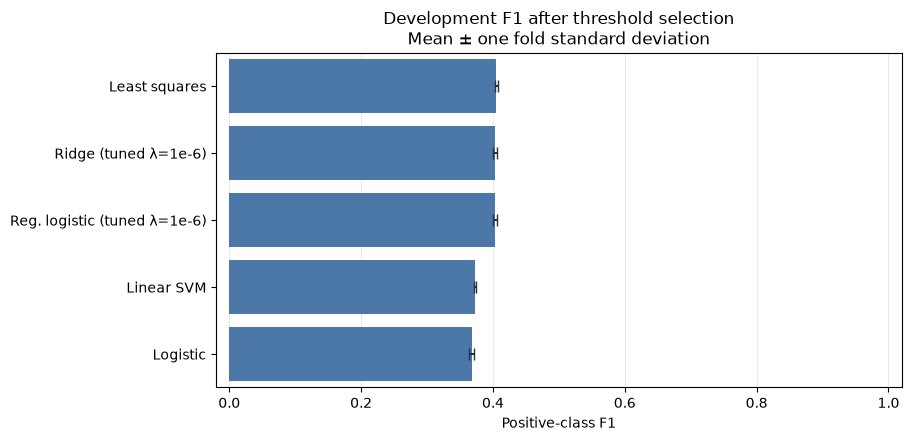

In [54]:

# 6. Report + plot
Path("results").mkdir(exist_ok=True)
comparison2.save_report(
    tuned_thr, "results/model_comparison.json",
    metadata={"dataset": "BRFSS", "preprocessing": "preproc_MSCOHE",
              "num_mask": NUM_MASK.tolist(), "cat_mask": CAT_MASK.tolist()},
)
fig, ax = plot_model_comparison(tuned_thr)
fig.savefig("results/model_comparison_f1.png", dpi=150, bbox_inches="tight")
plt.show()


In [64]:
kept_indices = np.array([labels.index(name) for name in KEPT_NAMES])
kept_indices

array([ 26,  27,  28,  30,  31,  32,  33,  38,  39,  42,  43,  44,  45,
        46,  47,  48,  50,  51,  52,  53,  57,  58,  59,  60,  61,  65,
        66,  67,  68,  69,  70,  71,  76,  87,  99, 100, 103, 104, 232,
       233, 237, 242, 246, 253, 259, 262, 263, 265, 276, 277, 297, 301,
       304])

In [ ]:

# 7. Holdout final

X_hold_sub = X_hold[:, kept_indices]

dev_ids  = development["ids"]    
hold_ids = holdout["ids"]        

development_sub = {"X": X_dev_sub,  "y": y_dev,  "ids": dev_ids}
holdout_sub     = {"X": X_hold_sub, "y": y_hold, "ids": hold_ids}

best_name = next(iter(tuned_thr))     # sorted by mean F1
best_config = tuned_thr[best_name]["configuration"]
final = HoldoutEvaluator(best_config, preprocessor_factory=factory)
holdout_result = final.evaluate(development_sub, holdout_sub)
final.save_report(
    holdout_result, "results/holdout_evaluation.json",
    metadata={"selected_candidate": best_name,
              "selection_data": "development_oof",
              "preprocessing": "preproc_MSCOHE"},
)
print(holdout_result["metrics"])
print(holdout_result["confusion_matrix"])

{'accuracy': 0.8293994849680771, 'precision': 0.2892703862660944, 'recall': 0.6396893874029336, 'f1': 0.3983879634605051, 'roc_auc': 0.8393183946398781}
{'labels': [-1, 1], 'rows': 'actual', 'columns': 'predicted', 'values': [[50724, 9108], [2088, 3707]]}
